# Pakistan car number plate dataset: what is actually in it

A Roboflow export (YOLO format) published twice on Kaggle by the same author with identical contents:

- https://www.kaggle.com/datasets/musakhanalabazy/pakistan-car-number-plate
- https://www.kaggle.com/datasets/musakhanalabazy/pakistan-car-number-plate-data-set

12,322 images at 640x640, 37 classes (digits, letters and `LicensePlate`). It is an image dataset, so there is no
table to load directly. `prepare_annotations.py` reads every label file from the raw download and writes
`number_plates_annotations.csv`, one row per annotation. This notebook only needs that CSV, not the 630 MB of images.

Plate numbers identify real vehicles, so nothing here prints a full plate string. Only counts and aggregate patterns.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import Image as show_image

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

charts = Path("charts")
charts.mkdir(exist_ok=True)

blue, orange, aqua, grey = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": grey, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "figure.facecolor": "white", "axes.facecolor": "white",
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(charts / name, bbox_inches="tight")

## Loading and a first look

In [2]:
raw = pd.read_csv("number_plates_annotations.csv")
print(raw.shape)
raw.head()

(24534, 19)


,split,image_file,source_id,rf_hash,image_bytes,image_md5,img_width,img_height,has_label_file,box_index,class_id,class_name,x_center,y_center,width,height,label_format,n_points,n_values
0,train,-1024x480_jpg.rf.1ceb76aee985d8b80c90b66b4d0f4...,-1024x480_jpg,1ceb76aee985d8b80c90b66b4d0f4f8f,25600,67d0223464625d25cc5b312dd1dab750,640,640,True,0,22.0,LicensePlate,0.500000,0.440625,1.000000,0.880469,box,0.0,4.0
1,train,-1024x480_jpg.rf.1ceb76aee985d8b80c90b66b4d0f4...,-1024x480_jpg,1ceb76aee985d8b80c90b66b4d0f4f8f,25600,67d0223464625d25cc5b312dd1dab750,640,640,True,1,5.0,5,0.170313,0.266406,0.340625,0.532813,box,0.0,4.0
2,train,-1024x480_jpg.rf.1ceb76aee985d8b80c90b66b4d0f4...,-1024x480_jpg,1ceb76aee985d8b80c90b66b4d0f4f8f,25600,67d0223464625d25cc5b312dd1dab750,640,640,True,2,6.0,6,0.535156,0.264844,0.341406,0.529687,box,0.0,4.0
3,train,-1024x480_jpg.rf.1ceb76aee985d8b80c90b66b4d0f4...,-1024x480_jpg,1ceb76aee985d8b80c90b66b4d0f4f8f,25600,67d0223464625d25cc5b312dd1dab750,640,640,True,3,7.0,7,0.857031,0.271094,0.285938,0.542188,box,0.0,4.0
4,train,-1024x480_jpg.rf.6e33890e8c0d0631d626ffbab0fa2...,-1024x480_jpg,6e33890e8c0d0631d626ffbab0fa2af8,21385,94fde6dca26632adf4b0f585177fdcb8,640,640,True,0,22.0,LicensePlate,0.500000,0.440625,1.000000,0.880469,box,0.0,4.0


Columns, as written by the prepare script:

- `split`, `image_file`: where the image sits in the download
- `source_id`, `rf_hash`: the two halves of the Roboflow file name `<source-id>.rf.<hash>.jpg`
- `image_bytes`, `image_md5`, `img_width`, `img_height`: taken from the jpg file itself
- `box_index`: line number inside the label file, or -1 for an image whose label file is empty
- `class_id`, `class_name`: class as listed in `data.yaml`
- `x_center`, `y_center`, `width`, `height`: the box, as fractions of the image
- `label_format`, `n_points`, `n_values`: whether the original line was a plain box (4 numbers) or a polygon

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 24534 entries, 0 to 24533
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   split           24534 non-null  str    
 1   image_file      24534 non-null  str    
 2   source_id       24534 non-null  str    
 3   rf_hash         24534 non-null  str    
 4   image_bytes     24534 non-null  int64  
 5   image_md5       24534 non-null  str    
 6   img_width       24534 non-null  int64  
 7   img_height      24534 non-null  int64  
 8   has_label_file  24534 non-null  bool   
 9   box_index       24534 non-null  int64  
 10  class_id        23311 non-null  float64
 11  class_name      23311 non-null  str    
 12  x_center        23311 non-null  float64
 13  y_center        23311 non-null  float64
 14  width           23311 non-null  float64
 15  height          23311 non-null  float64
 16  label_format    23311 non-null  str    
 17  n_points        23311 non-null  float64
 1

In [4]:
print("images:", raw["image_file"].nunique())
print("image sizes seen:", raw[["img_width", "img_height"]].drop_duplicates().values.tolist())
print("images without a label file:", (~raw["has_label_file"]).sum())
print()
print("missing values per column")
print(raw.isna().sum()[raw.isna().sum() > 0])

images: 12322
image sizes seen: [[640, 640]]
images without a label file: 0

missing values per column
class_id        1223
class_name      1223
x_center        1223
y_center        1223
width           1223
height          1223
label_format    1223
n_points        1223
n_values        1223
dtype: int64


The only missing values are the box columns on the 1,223 placeholder rows for images with an empty label file.
Every image has a label file and every image really is 640x640.

I will work with two tables from here: one row per image, and one row per box.

In [5]:
images = raw.drop_duplicates("image_file")[
    ["split", "image_file", "source_id", "rf_hash", "image_bytes", "image_md5"]].reset_index(drop=True)
boxes = raw[raw["box_index"] >= 0].copy()
boxes["class_id"] = boxes["class_id"].astype(int)
boxes["is_plate"] = boxes["class_name"] == "LicensePlate"

print(len(images), "images,", len(boxes), "boxes")
print(images["split"].value_counts())

12322 images, 23311 boxes
split
train    11172
valid      664
test       486
Name: count, dtype: int64


## Checking the label format

In [6]:
print(boxes["label_format"].value_counts())
print()
print("values per label line:")
print(boxes["n_values"].astype(int).value_counts().sort_index())
print()
print("polygon rows by class:", boxes.loc[boxes["label_format"] == "polygon", "class_name"].unique())
poly_imgs = boxes.loc[boxes["label_format"] == "polygon", "image_file"].nunique()
print("images with at least one polygon row:", poly_imgs)

label_format
box        19014
polygon     4297
Name: count, dtype: int64

values per label line:
n_values
4     19014
8       131
10     2065
12     1061
14      774
16      202
18       36
20       12
22        8
24        7
32        1
Name: count, dtype: int64

polygon rows by class: <StringArray>
['LicensePlate']
Length: 1, dtype: str
images with at least one polygon row: 4227


So the export is mixed. 19,014 lines are ordinary boxes, but 4,297 lines are polygons with 4 to 16 points, and every
one of them is a `LicensePlate`. A parser that assumed five numbers per line would either crash or silently misread
more than a third of the plate annotations. The prepare script replaces each polygon by the box that encloses it, so
all rows are comparable from here on. `label_format` keeps track of which ones were converted.

In [7]:
x0 = boxes["x_center"] - boxes["width"] / 2
x1 = boxes["x_center"] + boxes["width"] / 2
y0 = boxes["y_center"] - boxes["height"] / 2
y1 = boxes["y_center"] + boxes["height"] / 2
tol = 1e-5
print("class ids outside 0-36:", (~boxes["class_id"].between(0, 36)).sum())
print("boxes reaching outside the image:", ((x0 < -tol) | (x1 > 1 + tol) | (y0 < -tol) | (y1 > 1 + tol)).sum())
print("boxes with zero or negative size:", ((boxes["width"] <= 0) | (boxes["height"] <= 0)).sum())

boxes["w_px"] = boxes["width"] * 640
boxes["h_px"] = boxes["height"] * 640
sliver = (boxes["w_px"] < 2) | (boxes["h_px"] < 2)
print("boxes thinner than 2 pixels in one direction:", sliver.sum())
print(boxes.loc[sliver, "class_name"].value_counts().to_dict())
print("identical box repeated within one image:",
      boxes.duplicated(["image_file", "class_id", "x_center", "y_center", "width", "height"]).sum())

class ids outside 0-36: 0
boxes reaching outside the image: 0
boxes with zero or negative size: 0
boxes thinner than 2 pixels in one direction: 13
{'LicensePlate': 13}
identical box repeated within one image: 0


Coordinates are all inside the image and class ids are valid. A handful of boxes are slivers less than two pixels
wide or tall, which is what is left of an object after a crop cut almost all of it away. They carry no usable
signal, so they get dropped in the cleaning step.

## Duplicate images and repeated sources

Two different questions here. First, are any files exact repeats? Second, the file names look like
`<source-id>.rf.<hash>.jpg`, so how many distinct source images are there behind the 12,322 files?

In [8]:
md5_counts = images["image_md5"].value_counts()
dup_md5 = md5_counts[md5_counts > 1]
print("distinct image files by content:", images["image_md5"].nunique(), "of", len(images))
print("byte-identical groups:", len(dup_md5), " extra copies:", int((dup_md5 - 1).sum()))

dups = images[images["image_md5"].isin(dup_md5.index)]
across = dups.groupby("image_md5")["split"].nunique()
print("identical files that sit in two different splits:", (across > 1).sum())
print(dups.groupby("image_md5")["split"].apply(lambda s: " + ".join(sorted(s))).value_counts())

# do the identical files also carry the same labels?
dups = dups.assign(n_boxes=dups["image_file"].map(boxes.groupby("image_file").size()).fillna(0).astype(int))
pair_counts = dups.sort_values("n_boxes").groupby("image_md5")["n_boxes"].apply(tuple)
print()
print("box counts of the two copies (fewer, more):")
print(pair_counts.value_counts())

distinct image files by content: 12273 of 12322
byte-identical groups: 49  extra copies: 49
identical files that sit in two different splits: 12
split
train + train    34
test + train      8
train + valid     4
test + test       3
Name: count, dtype: int64

box counts of the two copies (fewer, more):
n_boxes
(1, 1)    34
(0, 0)    10
(1, 8)     3
(1, 5)     1
(2, 2)     1
Name: count, dtype: int64


49 files are byte-for-byte repeats of another file, always under the same source id, and 12 of those pairs straddle
two splits. In 45 pairs the two copies have the same number of boxes (the polygon corners differ by a hair, as if the
image was annotated twice). In 4 pairs one copy has only the plate box and the other has the characters as well, so
the same picture is labelled two different ways.

In [9]:
per_source = images.groupby("source_id").agg(
    copies=("image_file", "size"),
    splits=("split", lambda s: "+".join(sorted(set(s)))),
    n_splits=("split", "nunique"),
)
print("distinct source ids:", len(per_source))
print("images per source: median", per_source["copies"].median(), " mean", round(per_source["copies"].mean(), 2),
      " max", per_source["copies"].max())
print("sources with an odd number of copies:", (per_source["copies"] % 2 == 1).sum())
print()
print(per_source["splits"].value_counts())

distinct source ids: 1748
images per source: median 2.0  mean 7.05  max 54
sources with an odd number of copies: 0

splits
train               1263
valid                178
test+train           115
train+valid           94
test                  58
test+train+valid      32
test+valid             8
Name: count, dtype: int64


In [10]:
leaky = per_source[per_source["n_splits"] > 1]
images["source_copies"] = images["source_id"].map(per_source["copies"])
images["source_in_multiple_splits"] = images["source_id"].isin(leaky.index)

print("sources that appear in more than one split:", len(leaky), f"({len(leaky) / len(per_source):.1%} of sources)")
leak_tab = images.groupby("split").agg(images=("image_file", "size"),
                                       from_shared_source=("source_in_multiple_splits", "sum"))
train_sources = set(images.loc[images["split"] == "train", "source_id"])
leak_tab["source_also_in_train"] = images[images["source_id"].isin(train_sources)].groupby("split").size()
leak_tab["share_also_in_train"] = (leak_tab["source_also_in_train"] / leak_tab["images"]).round(3)
leak_tab

sources that appear in more than one split: 249 (14.2% of sources)


,images,from_shared_source,source_also_in_train,share_also_in_train
split,,,,
test,486,368,352,0.724
train,11172,3590,11172,1.000
valid,664,300,284,0.428


This is the most important thing in the dataset. There are 12,322 files but only 1,748 distinct source images, so on
average each source photo appears about seven times (the median is two), and one appears 54 times. Every source has an even
number of copies.

The Roboflow README says "No image augmentation techniques were applied", yet the copies of one source are not
identical files (only 49 files are byte-for-byte repeats). Looking at them, they are different crops and tiles of the
same photo with speckle noise and brightness changes added. So the augmentation was baked in before this export
(most likely the tiles were uploaded as source images), and the README statement only describes the final export step.
I cannot tell from the files alone exactly which transforms were used.

It also means the split is leaky: 249 sources have copies in more than one split. The table above shows how much of
valid and test comes from a photo that the training set also contains.

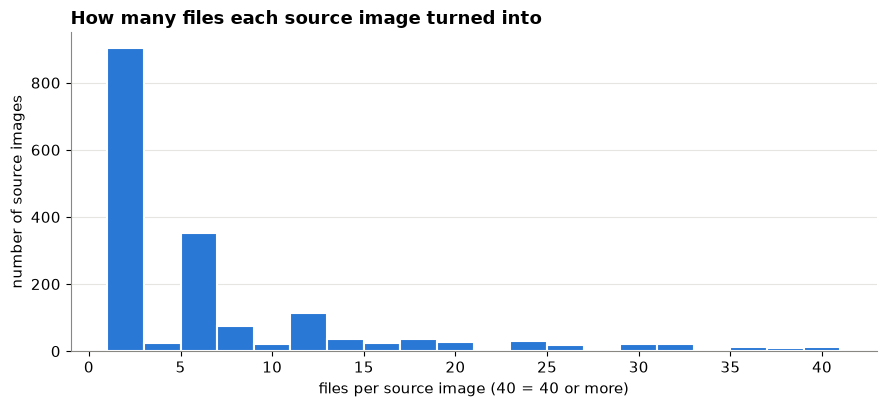

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.2))
top = per_source["copies"].clip(upper=40)
ax.hist(top, bins=np.arange(1, 43, 2), color=blue, edgecolor="white", linewidth=1.5)
ax.set_title("How many files each source image turned into")
ax.set_xlabel("files per source image (40 = 40 or more)")
ax.set_ylabel("number of source images")
ax.grid(axis="x", visible=False)
save(fig, "01_copies_per_source.png")
plt.show()

### Where the source images seem to come from

The source ids fall into a few naming patterns. This is only the file name, so it hints at how the images were
collected, not where the cars are.

In [12]:
def name_pattern(s):
    if s.startswith("syn_"):
        return "syn_<number>"
    if "augmented" in s:
        return "<name>_augmented<n>"
    if re.fullmatch(r"[0-9a-f]{16,17}_jpg", s):
        return "16-digit hex id"
    if re.match(r"[0-9a-f]{8}-[0-9a-f]{4}-", s):
        return "uuid"
    if re.search(r"-\d{4}-\d{6,}(-\d+)?_jpe?g", s):
        return "car listing (model-year-id)"
    if re.fullmatch(r"[0-9a-z]{13}_jpg", s):
        return "13-character id"
    return "other names"

images["name_pattern"] = images["source_id"].map(name_pattern)
n_boxes = boxes.groupby("image_file").size()
n_chars = boxes[~boxes["is_plate"]].groupby("image_file").size()
n_plates = boxes[boxes["is_plate"]].groupby("image_file").size()
images["n_boxes"] = images["image_file"].map(n_boxes).fillna(0).astype(int)
images["n_chars"] = images["image_file"].map(n_chars).fillna(0).astype(int)
images["n_plates"] = images["image_file"].map(n_plates).fillna(0).astype(int)

by_pattern = images.groupby("name_pattern").agg(
    sources=("source_id", "nunique"), images=("image_file", "size"),
    no_labels=("n_boxes", lambda s: (s == 0).sum()),
    with_characters=("n_chars", lambda s: (s > 0).sum()),
).sort_values("images", ascending=False)
by_pattern["files_per_source"] = (by_pattern["images"] / by_pattern["sources"]).round(1)
by_pattern["share_with_characters"] = (by_pattern["with_characters"] / by_pattern["images"]).round(3)
by_pattern

,sources,images,no_labels,with_characters,files_per_source,share_with_characters
name_pattern,,,,,,
13-character id,210,4522,734,147,21.5,0.033
16-digit hex id,390,2662,0,642,6.8,0.241
uuid,197,2160,240,1003,11.0,0.464
other names,161,1398,159,62,8.7,0.044
<name>_augmented<n>,412,824,0,821,2.0,0.996
car listing (model-year-id),284,568,90,434,2.0,0.764
syn_<number>,94,188,0,188,2.0,1.000


In [13]:
# a rough count of source names that openly point somewhere other than Pakistan, or to generated images
hints = ["spanje", "nederland", "matricula", "south-sudan", "northcal", "dall-e", "syn_"]
low = per_source.index.str.lower()
for h in hints:
    print(f"{h:12s} {low.str.contains(h, regex=False).sum():4d} sources")

spanje          8 sources
nederland       1 sources
matricula       5 sources
south-sudan     2 sources
northcal       11 sources
dall-e          5 sources
syn_           94 sources


The name "Pakistan car number plate" does not match everything in here. A group of sources is named like Pakistani
car listings (model, year, listing id), but others carry Dutch or Spanish words for Spain, the Netherlands and "number plate", 94 are called `syn_`
(which reads like synthetic, though the files do not say so), and five are named after an image generator.
The sample sheet below also shows plates that are clearly not Pakistani. I cannot put a number on the Pakistani share from
annotations alone, so I am only saying that it is a mixed-country collection.

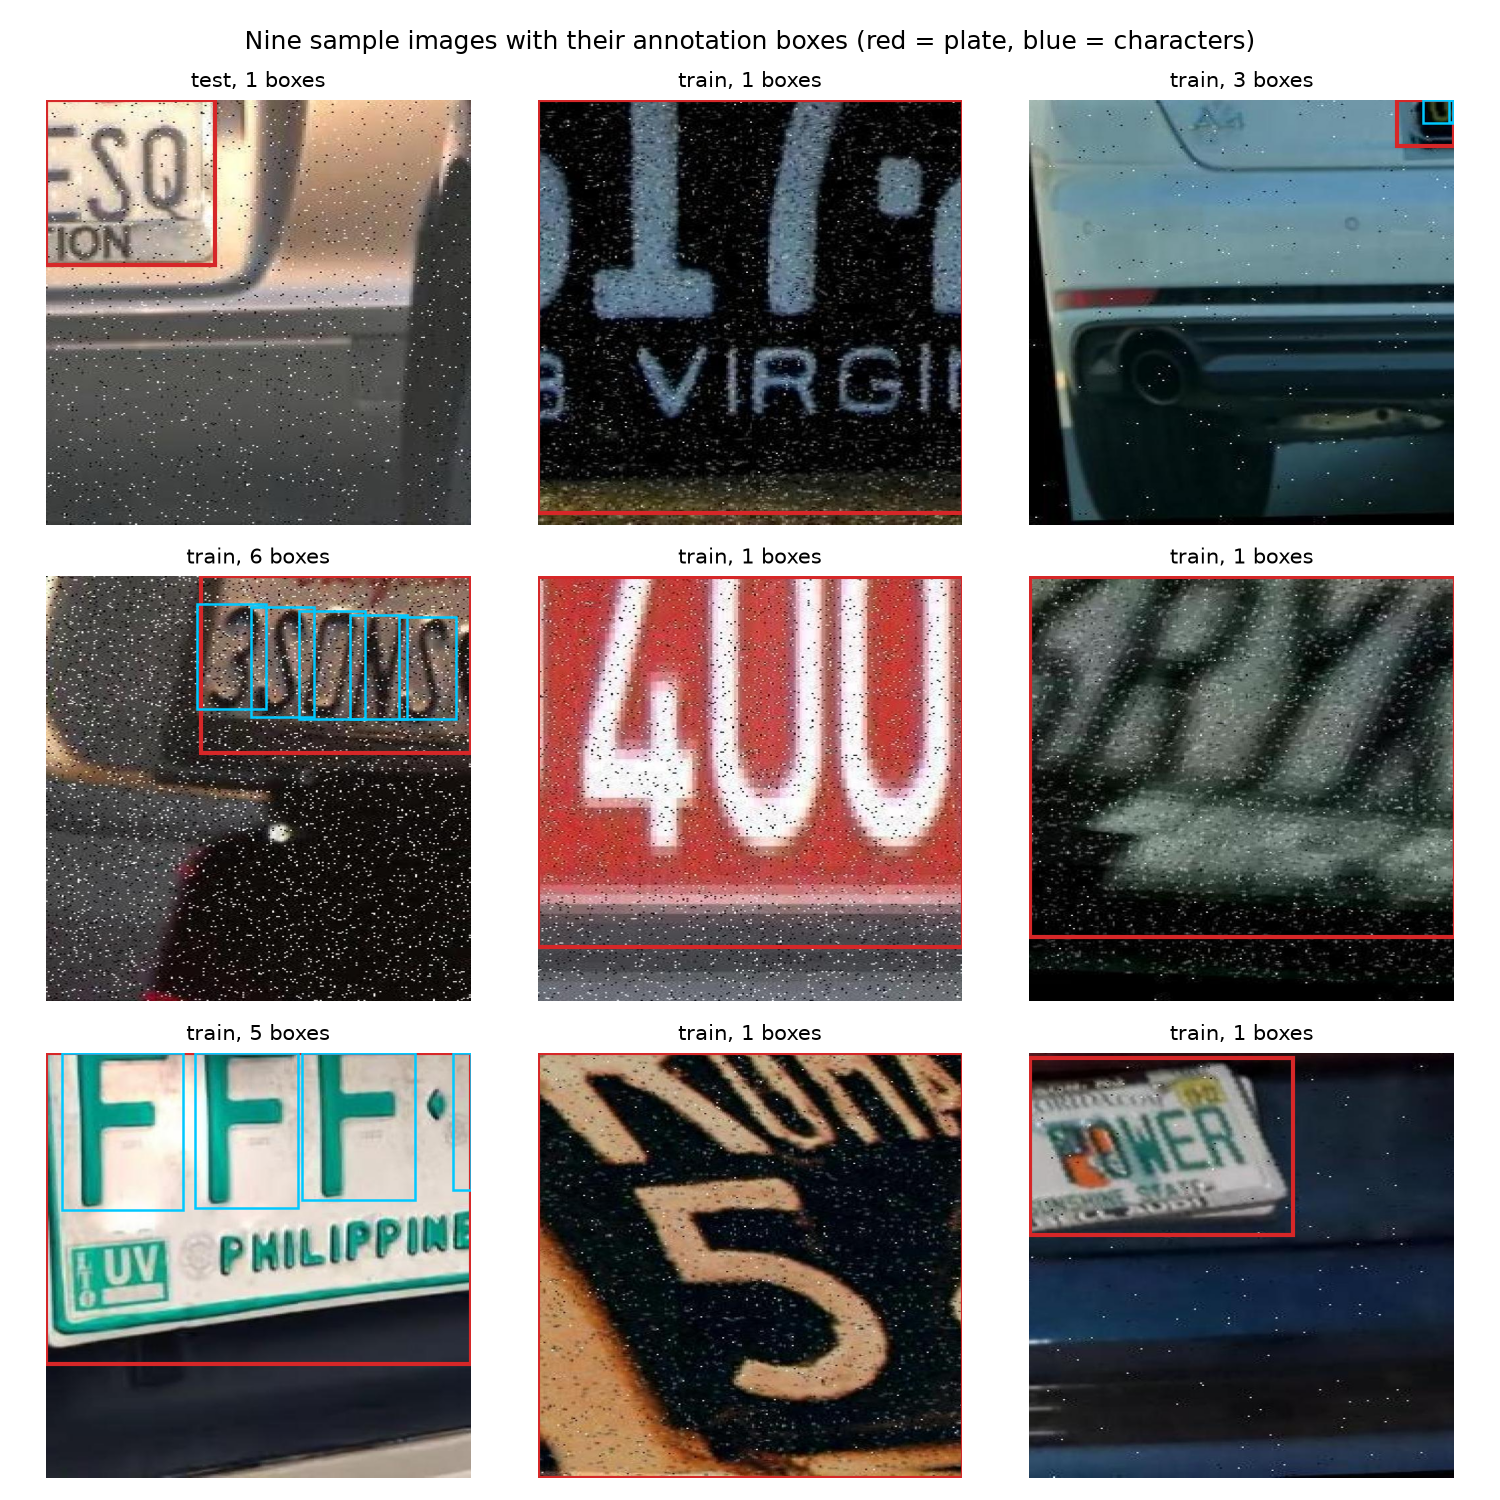

In [14]:
show_image(filename="charts/00_sample_images_contact_sheet.png", width=700)

(The sheet above is drawn by `prepare_annotations.py`, because it needs the image files. Nine labelled images picked
with a fixed random seed.) The speckle noise and tight crops are visible in most of them.

## Cleaning

What I change, and why:

1. Polygon rows are already converted to enclosing boxes by the prepare script (4,297 rows, all plates).
2. Drop the extra copy of each byte-identical image. I keep the copy with more boxes (the fuller annotation), and
   where that is a tie, the one in valid/test rather than train.
3. Drop sliver boxes under 2 px.
4. Keep the unlabelled images, as one row each with empty box columns and `is_background = True`. They may be
   intentional background examples, and dropping them would hide a tenth of the dataset.
5. Add the columns worked out above (`name_pattern`, `source_copies`, `source_in_multiple_splits`) plus per-image box
   counts, so anyone rebuilding the split can group by `source_id`.

I do not re-split the data. That is a modelling decision; the flag is there for it.

In [15]:
order = {"test": 0, "valid": 1, "train": 2}
ranked = images.assign(rank=images["split"].map(order)).sort_values(
    ["image_md5", "n_boxes", "rank", "image_file"], ascending=[True, False, True, True])
drop_files = set(ranked.loc[ranked.duplicated("image_md5"), "image_file"])
print("image files dropped as exact duplicates:", len(drop_files))
print(images[images["image_file"].isin(drop_files)]["split"].value_counts().to_dict())

images_clean = images[~images["image_file"].isin(drop_files)].copy()
boxes_clean = boxes[~boxes["image_file"].isin(drop_files) & ~sliver].copy()
print("boxes dropped with the duplicate images:", boxes["image_file"].isin(drop_files).sum())
print("sliver boxes dropped:", (sliver & ~boxes["image_file"].isin(drop_files)).sum())

# recount after dropping
for col, mask in [("n_boxes", slice(None)), ("n_chars", ~boxes_clean["is_plate"]), ("n_plates", boxes_clean["is_plate"])]:
    images_clean[col] = images_clean["image_file"].map(boxes_clean[mask].groupby("image_file").size()).fillna(0).astype(int)
images_clean["is_background"] = images_clean["n_boxes"] == 0
print()
print("images:", len(images), "->", len(images_clean))
print("boxes: ", len(boxes), "->", len(boxes_clean))
print("unlabelled images:", images_clean["is_background"].sum(), "(was", (images["n_boxes"] == 0).sum(), "before)")

image files dropped as exact duplicates: 49
{'train': 46, 'test': 3}
boxes dropped with the duplicate images: 40
sliver boxes dropped: 13

images: 12322 -> 12273
boxes:  23311 -> 23258
unlabelled images: 1224 (was 1223 before)


In [16]:
img_cols = ["split", "image_file", "source_id", "name_pattern", "source_copies", "source_in_multiple_splits",
            "image_bytes", "n_boxes", "n_plates", "n_chars", "is_background"]
box_cols = ["image_file", "box_index", "class_id", "class_name", "x_center", "y_center", "width", "height", "label_format"]
cleaned = images_clean[img_cols].merge(boxes_clean[box_cols], on="image_file", how="left")
cleaned["box_index"] = cleaned["box_index"].fillna(-1).astype(int)
cleaned["class_id"] = cleaned["class_id"].astype("Int64")
cleaned = cleaned.sort_values(["split", "image_file", "box_index"]).reset_index(drop=True)
cleaned.to_csv("number_plates_cleaned.csv", index=False)
print("raw table:    ", raw.shape)
print("cleaned table:", cleaned.shape)

raw table:     (24534, 19)
cleaned table: (24482, 19)


The cleaned table has 52 fewer rows: 49 duplicate images (with their 40 boxes) and 13 sliver boxes are gone. Where
removing a sliver left an image with no boxes at all, that image now counts as unlabelled. Everything below uses
the cleaned tables.

In [17]:
images, boxes = images_clean, boxes_clean
plates = boxes[boxes["is_plate"]].copy()
chars = boxes[~boxes["is_plate"]].copy()
print(len(images), "images |", len(plates), "plate boxes |", len(chars), "character boxes")

12273 images | 11465 plate boxes | 11793 character boxes


## What is labelled

In [18]:
kinds = pd.Series(np.select(
    [images["n_boxes"] == 0, (images["n_plates"] > 0) & (images["n_chars"] == 0),
     (images["n_plates"] > 0) & (images["n_chars"] > 0)],
    ["no labels", "plate only", "plate and characters"], default="characters only"), index=images.index)
images["kind"] = kinds
kind_tab = images["kind"].value_counts().to_frame("images")
kind_tab["share"] = (kind_tab["images"] / len(images)).round(3)
print(kind_tab)
print()
print("plate boxes per image:")
print(images["n_plates"].value_counts().sort_index())

                      images  share
kind                               
plate only              7753  0.632
plate and characters    3242  0.264
no labels               1224  0.100
characters only           54  0.004

plate boxes per image:
n_plates
0     1278
1    10617
2      314
3       55
4        4
6        2
9        3
Name: count, dtype: int64


The 37 classes suggest a plate-reading dataset, but 63% of the images only have the plate outlined. Roughly a quarter
have any character boxes at all, and one in ten has no labels. Not every labelled image has exactly one
plate either: a few hundred have two or more, and 54 have characters with no plate box around them.

count    12273.00
mean         1.90
std          1.87
min          0.00
25%          1.00
50%          1.00
75%          3.00
max         17.00
Name: n_boxes, dtype: float64

character boxes per image, for images that have any:
count    3296.00
mean        3.58
std         1.55
min         1.00
25%         3.00
50%         3.00
75%         4.00
max        15.00
Name: n_chars, dtype: float64


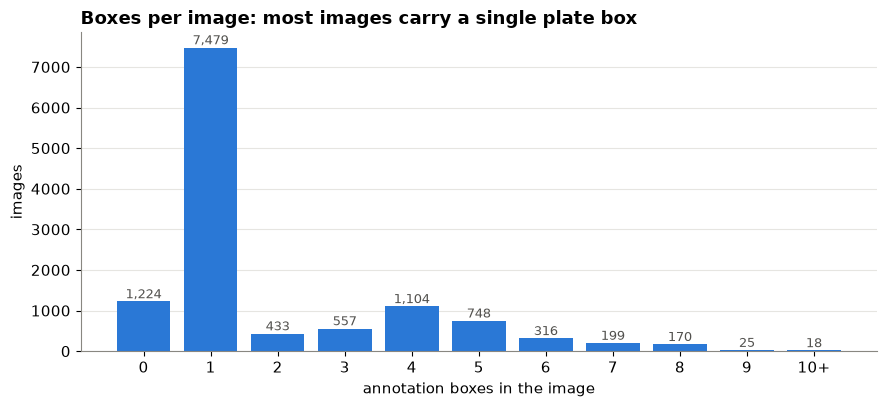

In [19]:
print(images["n_boxes"].describe().round(2))
print()
print("character boxes per image, for images that have any:")
print(images.loc[images["n_chars"] > 0, "n_chars"].describe().round(2))

fig, ax = plt.subplots(figsize=(9, 4.2))
counts = images["n_boxes"].clip(upper=10).value_counts().sort_index()
ax.bar(counts.index, counts.values, color=blue, width=0.8)
for x, v in counts.items():
    ax.text(x, v + 80, f"{v:,}", ha="center", fontsize=9, color="#52514e")
ax.set_xticks(range(11))
ax.set_xticklabels([str(i) for i in range(10)] + ["10+"])
ax.set_title("Boxes per image: most images carry a single plate box")
ax.set_xlabel("annotation boxes in the image")
ax.set_ylabel("images")
ax.grid(axis="x", visible=False)
save(fig, "02_boxes_per_image.png")
plt.show()

### Class frequencies

In [20]:
class_counts = boxes["class_name"].value_counts()
print("LicensePlate boxes:", class_counts["LicensePlate"], f"({class_counts['LicensePlate'] / len(boxes):.1%} of all boxes)")
char_counts = chars["class_name"].value_counts()
print("character boxes:", len(chars), " digits:", chars["class_name"].str.isdigit().sum(),
      " letters:", (~chars["class_name"].str.isdigit()).sum())
print()
print("most common:", char_counts.head(5).to_dict())
print("least common:", char_counts.tail(5).to_dict())
print("ratio most/least common character:", round(char_counts.iloc[0] / char_counts.iloc[-1], 2))
print("plate boxes per box of the rarest character:", round(class_counts["LicensePlate"] / char_counts.iloc[-1], 1))

LicensePlate boxes: 11465 (49.3% of all boxes)
character boxes: 11793  digits: 3368  letters: 8425

most common: {'A': 624, 'L': 564, 'E': 494, 'N': 484, 'B': 419}
least common: {'K': 226, 'V': 216, 'W': 215, 'Z': 155, 'X': 152}
ratio most/least common character: 4.11
plate boxes per box of the rarest character: 75.4


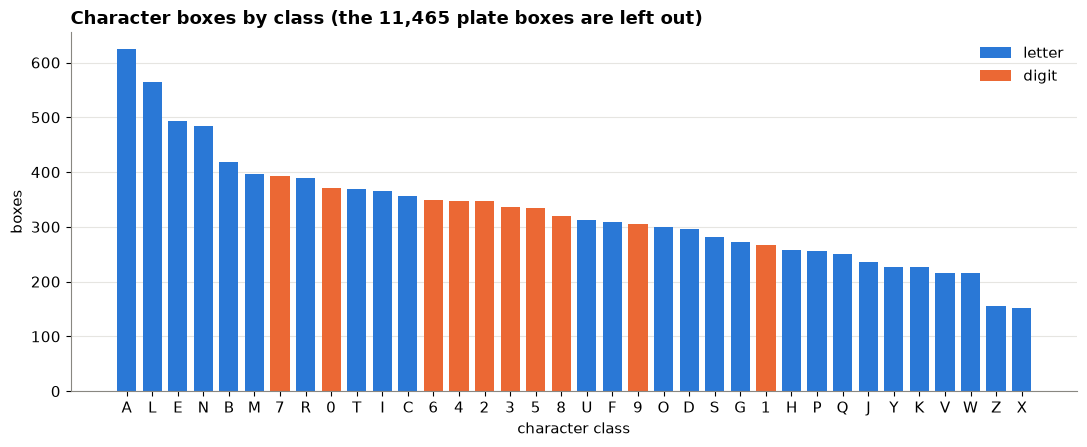

In [21]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ordered = char_counts.sort_values(ascending=False)
colors = [orange if c.isdigit() else blue for c in ordered.index]
ax.bar(ordered.index, ordered.values, color=colors, width=0.75)
ax.bar([0], [0], color=blue, label="letter")
ax.bar([0], [0], color=orange, label="digit")
ax.legend(frameon=False)
ax.set_title("Character boxes by class (the 11,465 plate boxes are left out)")
ax.set_xlabel("character class")
ax.set_ylabel("boxes")
ax.grid(axis="x", visible=False)
save(fig, "03_character_class_counts.png")
plt.show()

The real class imbalance is between `LicensePlate` and everything else. Within the characters
the spread is modest: the most common letter has about four times as many boxes as the rarest. Digits are fairly
even. Keep in mind these counts include the repeated crops of the same photo, so they overstate how many
distinct examples of each character exist. Counting each character once per source image gives a fairer view:

In [22]:
src_of = images.set_index("image_file")["source_id"]
chars["source_id"] = chars["image_file"].map(src_of)
sources_per_class = chars.groupby("class_name")["source_id"].nunique().sort_values()
print("source images that contain each character at least once")
print("fewest:", sources_per_class.head(5).to_dict())
print("most:  ", sources_per_class.tail(5).to_dict())
print("sources with any character box:", chars["source_id"].nunique(), "of", images["source_id"].nunique())

source images that contain each character at least once
fewest: {'Z': 60, 'X': 75, 'O': 83, 'Y': 84, 'W': 92}
most:   {'7': 224, '0': 227, '5': 228, 'L': 234, 'A': 295}
sources with any character box: 1140 of 1748


### Split balance

In [23]:
split_tab = images.groupby("split").agg(
    images=("image_file", "size"), sources=("source_id", "nunique"),
    no_labels=("is_background", "sum"),
    with_characters=("n_chars", lambda s: (s > 0).sum()),
    boxes=("n_boxes", "sum"), char_boxes=("n_chars", "sum"),
).loc[["train", "valid", "test"]]
split_tab["share_of_images"] = (split_tab["images"] / len(images)).round(3)
split_tab["share_no_labels"] = (split_tab["no_labels"] / split_tab["images"]).round(3)
split_tab["share_with_characters"] = (split_tab["with_characters"] / split_tab["images"]).round(3)
print(split_tab.T)

per_split_class = chars.groupby(["class_name", "split"]).size().unstack(fill_value=0)
print()
print("character classes with fewer than 10 boxes in valid:", (per_split_class["valid"] < 10).sum(),
      " in test:", (per_split_class["test"] < 10).sum())
print("smallest per-class counts  valid:", per_split_class["valid"].min(), " test:", per_split_class["test"].min())

split                      train     valid     test
images                 11126.000   664.000  483.000
sources                 1504.000   312.000  213.000
no_labels               1138.000    41.000   45.000
with_characters         2682.000   580.000   34.000
boxes                  20061.000  2645.000  552.000
char_boxes              9681.000  2011.000  101.000
share_of_images            0.907     0.054    0.039
share_no_labels            0.102     0.062    0.093
share_with_characters      0.241     0.873    0.070

character classes with fewer than 10 boxes in valid: 0  in test: 36
smallest per-class counts  valid: 10  test: 0


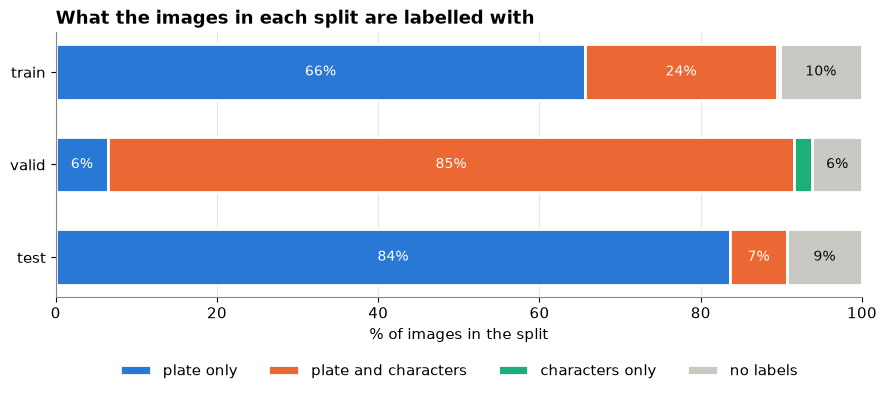

In [24]:
fig, ax = plt.subplots(figsize=(9, 4.2))
share = (images.groupby("split")["kind"].value_counts(normalize=True).unstack(fill_value=0)
         .loc[["train", "valid", "test"], ["plate only", "plate and characters", "characters only", "no labels"]])
left = np.zeros(3)
for col, color in zip(share.columns, [blue, orange, aqua, "#c9c8c2"]):
    ax.barh(share.index, share[col] * 100, left=left, color=color, edgecolor="white", linewidth=2, label=col, height=0.6)
    for i, v in enumerate(share[col] * 100):
        if v >= 6:
            ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=10,
                    color="white" if color != "#c9c8c2" else "#0b0b0b")
    left += share[col].values * 100
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_title("What the images in each split are labelled with")
ax.set_xlabel("% of images in the split")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
save(fig, "04_split_composition.png")
plt.show()

The split is about 91 / 5 / 4 by images, not the usual 70/20/10, and the three splits are not the same kind of
data. 87% of validation images have character boxes, against 24% in train and 7% in test. The test split has only
101 character boxes in total, every character class has fewer than ten there and some have none. So the shipped
test set can measure plate detection, but it cannot say anything reliable about character recognition.

## Box sizes and positions

In [25]:
plates["area"] = plates["width"] * plates["height"]
chars["area"] = chars["width"] * chars["height"]
plates["aspect"] = plates["w_px"] / plates["h_px"]
chars["aspect"] = chars["w_px"] / chars["h_px"]

print("plate boxes (fractions of the image, pixels at 640x640)")
print(plates[["width", "height", "area", "w_px", "h_px", "aspect"]].describe().round(3))
print()
print("plate boxes covering more than half the image:", (plates["area"] > 0.5).sum(), f"({(plates['area'] > 0.5).mean():.1%})")
print("plate boxes covering under 1% of the image:", (plates["area"] < 0.01).sum(), f"({(plates['area'] < 0.01).mean():.1%})")
touch = ((plates["x_center"] - plates["width"] / 2 < 0.005) | (plates["x_center"] + plates["width"] / 2 > 0.995) |
         (plates["y_center"] - plates["height"] / 2 < 0.005) | (plates["y_center"] + plates["height"] / 2 > 0.995))
print("plate boxes touching an image edge:", touch.sum(), f"({touch.mean():.1%})")
print("plate boxes taller than wide:", (plates["aspect"] < 1).sum(), f"({(plates['aspect'] < 1).mean():.1%})")

plate boxes (fractions of the image, pixels at 640x640)
           width     height       area       w_px       h_px     aspect
count  11465.000  11465.000  11465.000  11465.000  11465.000  11465.000
mean       0.601      0.476      0.388    384.569    304.868      1.542
std        0.350      0.337      0.391    223.732    215.799      1.215
min        0.003      0.007      0.000      2.003      4.475      0.012
25%        0.292      0.177      0.051    187.000    113.000      1.000
50%        0.528      0.341      0.163    338.000    218.000      1.234
75%        1.000      0.849      0.847    640.000    543.500      1.878
max        1.000      1.000      1.000    640.000    640.000     82.848

plate boxes covering more than half the image: 4112 (35.9%)
plate boxes covering under 1% of the image: 523 (4.6%)
plate boxes touching an image edge: 10521 (91.8%)
plate boxes taller than wide: 1847 (16.1%)


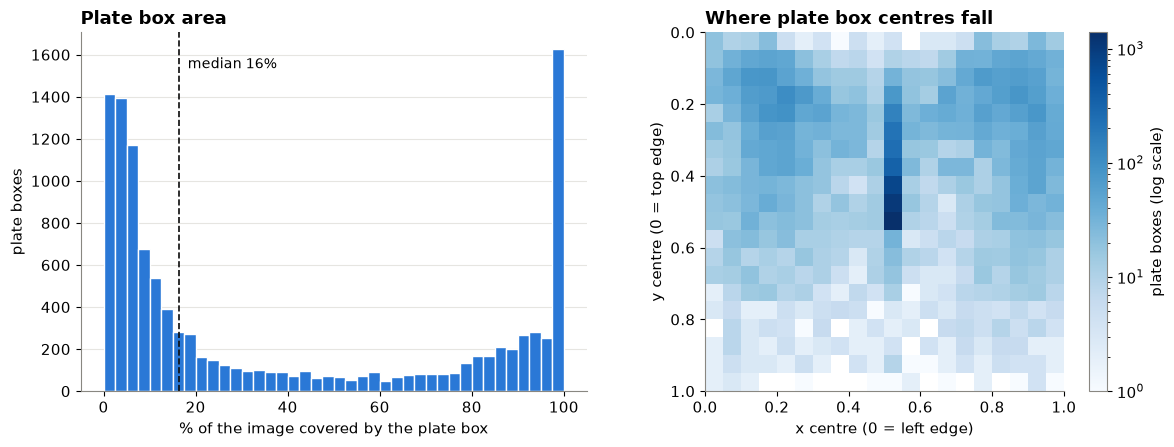

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
ax.hist(plates["area"] * 100, bins=40, color=blue, edgecolor="white", linewidth=1)
ax.axvline(plates["area"].median() * 100, color="#0b0b0b", linewidth=1.2, linestyle="--")
ax.text(plates["area"].median() * 100 + 2, ax.get_ylim()[1] * 0.9, f"median {plates['area'].median() * 100:.0f}%", fontsize=10)
ax.set_title("Plate box area")
ax.set_xlabel("% of the image covered by the plate box")
ax.set_ylabel("plate boxes")
ax.grid(axis="x", visible=False)

ax = axes[1]
hb = ax.hist2d(plates["x_center"], plates["y_center"], bins=20, range=[[0, 1], [0, 1]], cmap="Blues", norm=LogNorm(vmin=1))
ax.invert_yaxis()
ax.set_aspect("equal")
ax.grid(False)
ax.set_title("Where plate box centres fall")
ax.set_xlabel("x centre (0 = left edge)")
ax.set_ylabel("y centre (0 = top edge)")
fig.colorbar(hb[3], ax=ax, label="plate boxes (log scale)")
save(fig, "05_plate_size_and_position.png")
plt.show()

These are not photos of cars with a small plate somewhere. The median plate box covers 16% of the frame, more than a
third cover over half of it, and nine in ten touch an image edge, which fits tight crops and tiles rather than whole-vehicle photos. The area histogram has two humps: many
small boxes from wider shots, and a spike of boxes that fill the whole frame. The dark column at x = 0.5 in the position map is the boxes that span the full width of the image. About one in six plate boxes is taller than wide, which
real plates rarely are: that is the 640x640 stretch plus crops that cut a plate in half.

In [27]:
print("character boxes")
print(chars[["width", "height", "w_px", "h_px", "aspect"]].describe().round(3))
print()
print("character boxes under 10 px tall:", (chars["h_px"] < 10).sum(), f"({(chars['h_px'] < 10).mean():.1%})")
size_by_class = chars.groupby("class_name")["aspect"].median().sort_values()
print("narrowest classes (median width/height):", size_by_class.head(3).round(2).to_dict())
print("widest classes:", size_by_class.tail(3).round(2).to_dict())

character boxes
           width     height       w_px       h_px     aspect
count  11793.000  11793.000  11793.000  11793.000  11793.000
mean       0.182      0.293    116.479    187.655      0.743
std        0.144      0.224     92.209    143.251      0.477
min        0.003      0.012      2.000      8.000      0.008
25%        0.066      0.102     42.000     65.000      0.488
50%        0.126      0.220     80.500    141.000      0.656
75%        0.300      0.465    192.000    297.500      0.904
max        1.000      1.000    640.000    640.000      7.111

character boxes under 10 px tall: 1 (0.0%)
narrowest classes (median width/height): {'I': 0.55, 'Q': 0.58, 'V': 0.59}
widest classes: {'2': 0.73, '5': 0.76, 'J': 0.79}


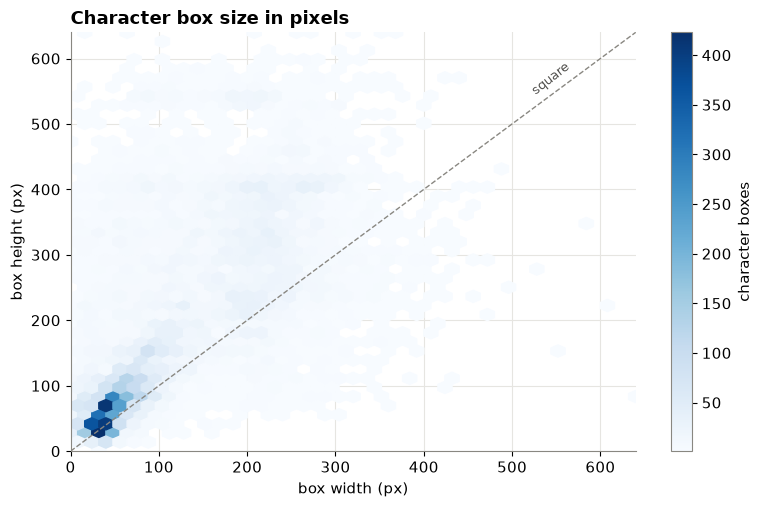

In [28]:
fig, ax = plt.subplots(figsize=(8, 5.2))
hb = ax.hexbin(chars["w_px"], chars["h_px"], gridsize=40, cmap="Blues", mincnt=1, extent=(0, 640, 0, 640))
ax.plot([0, 640], [0, 640], color=grey, linewidth=1, linestyle="--")
ax.text(520, 545, "square", color="#52514e", fontsize=9, rotation=38)
ax.set_xlim(0, 640); ax.set_ylim(0, 640)
ax.set_title("Character box size in pixels")
ax.set_xlabel("box width (px)")
ax.set_ylabel("box height (px)")
fig.colorbar(hb, ax=ax, label="character boxes")
save(fig, "06_character_box_sizes.png")
plt.show()

## Group comparison: unlabelled images

In [29]:
bg = images.groupby("is_background").agg(images=("image_file", "size"), sources=("source_id", "nunique"),
                                         median_bytes=("image_bytes", "median"))
print(bg)
print()
src_bg = images.groupby("source_id")["is_background"].agg(["sum", "size"])
print("sources where every copy is unlabelled:", (src_bg["sum"] == src_bg["size"]).sum())
print("sources with a mix of labelled and unlabelled copies:", ((src_bg["sum"] > 0) & (src_bg["sum"] < src_bg["size"])).sum())
print("unlabelled images that come from such mixed sources:",
      images.loc[images["is_background"] & images["source_id"].isin(src_bg[src_bg["sum"] < src_bg["size"]].index)].shape[0])

               images  sources  median_bytes
is_background                               
False           11049     1731       40154.0
True             1224      312       39312.0

sources where every copy is unlabelled: 17
sources with a mix of labelled and unlabelled copies: 295
unlabelled images that come from such mixed sources: 1130


Most unlabelled images (1,130 of 1,224) belong to a source photo whose other copies do have a plate labelled. That fits tiles
cut from a part of the photo where there is no plate, so they look like genuine background examples rather than
forgotten annotations. I have not looked at each one, so some could still be missed labels.

## Rough reconstruction of the plate text

Where an image has exactly one plate box and some character boxes, the characters can be read left to right to get
a string. This is approximate, for several reasons: only about a quarter of the images have characters, crops cut
plates so many strings are fragments, two-line plates would be read wrongly so I keep only images where the
characters sit on one line, and repeated crops of one photo count several times. No strings are printed or saved,
only their lengths and the type of the first character.

In [30]:
one_plate = images.loc[(images["n_plates"] == 1) & (images["n_chars"] > 0), "image_file"]
p = plates[plates["image_file"].isin(one_plate)].set_index("image_file")
c = chars[chars["image_file"].isin(one_plate)].join(p[["x_center", "y_center", "width", "height"]], on="image_file", rsuffix="_p")

inside = ((c["x_center"] - c["x_center_p"]).abs() <= c["width_p"] / 2) & ((c["y_center"] - c["y_center_p"]).abs() <= c["height_p"] / 2)
print("images with one plate and characters:", len(one_plate))
print("character boxes whose centre lies inside the plate box:", f"{inside.mean():.1%}")
c = c[inside]

# one line of text = the vertical spread of the character centres is small next to their height
g = c.groupby("image_file")
one_line = (g["y_center"].max() - g["y_center"].min()) < 0.5 * g["height"].median()
print("images where the characters sit on one line:", one_line.sum(), "of", len(one_line))

c = c[c["image_file"].isin(one_line[one_line].index)].sort_values(["image_file", "x_center"])
text = c.groupby("image_file")["class_name"].agg("".join)
length = text.str.len()
print()
print("reconstructed strings:", len(text), " from", c["source_id"].nunique(), "source images")
print("length distribution:")
print(length.value_counts().sort_index())

images with one plate and characters: 3141
character boxes whose centre lies inside the plate box: 99.9%
images where the characters sit on one line: 2875 of 3139

reconstructed strings: 2875  from 998 source images
length distribution:
class_name
1     191
2     460
3    1038
4     657
5     263
6     143
7     123
Name: count, dtype: int64


In [31]:
first_is_letter = text.str[0].str.isalpha()
print("starts with a letter:", f"{first_is_letter.mean():.1%}", " starts with a digit:", f"{(~first_is_letter).mean():.1%}")
print("letters only:", f"{text.str.fullmatch('[A-Z]+').mean():.1%}",
      " digits only:", f"{text.str.fullmatch('[0-9]+').mean():.1%}",
      " mixed:", f"{(~text.str.fullmatch('[A-Z]+') & ~text.str.fullmatch('[0-9]+')).mean():.1%}")
pk_like = text.str.fullmatch("[A-Z]{2,3}[0-9]{2,4}")
print("letters-then-digits shape (2-3 letters, 2-4 digits), the usual Pakistani layout:", f"{pk_like.mean():.1%}", f"({pk_like.sum()} strings)")
print()
print("most common first characters:", text.str[0].value_counts().head(8).to_dict())
print("share of strings with 5 or more characters:", f"{(length >= 5).mean():.1%}")
print("median length:", length.median())

starts with a letter: 79.3%  starts with a digit: 20.7%
letters only: 54.1%  digits only: 11.7%  mixed: 34.2%
letters-then-digits shape (2-3 letters, 2-4 digits), the usual Pakistani layout: 6.5% (188 strings)

most common first characters: {'A': 202, 'L': 201, 'B': 165, 'T': 121, 'N': 114, '4': 108, 'M': 105, 'C': 105}
share of strings with 5 or more characters: 18.4%
median length: 3.0


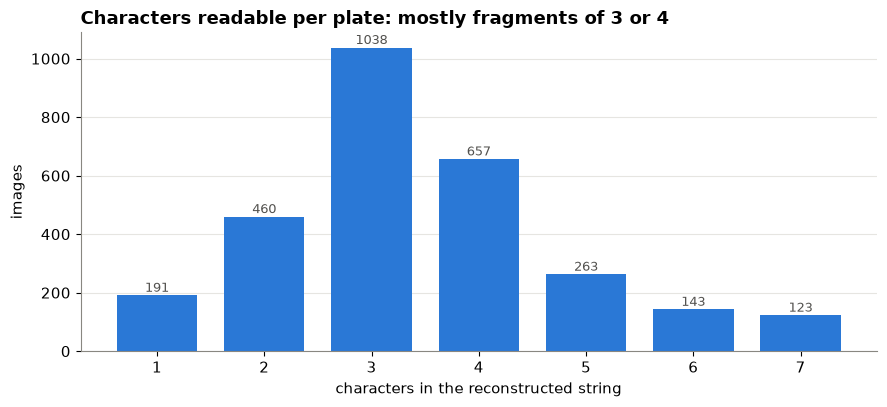

In [32]:
fig, ax = plt.subplots(figsize=(9, 4.2))
lc = length.value_counts().sort_index()
ax.bar(lc.index, lc.values, color=blue, width=0.75)
for x, v in lc.items():
    ax.text(x, v + 12, str(v), ha="center", fontsize=9, color="#52514e")
ax.set_xticks(range(1, int(lc.index.max()) + 1))
ax.set_title("Characters readable per plate: mostly fragments of 3 or 4")
ax.set_xlabel("characters in the reconstructed string")
ax.set_ylabel("images")
ax.grid(axis="x", visible=False)
save(fig, "07_reconstructed_plate_length.png")
plt.show()

The strings are short. A full plate normally has six or seven characters, but the typical reconstruction here has
three, because the crops show only part of the plate (or only part was annotated). Only a small minority have the
letters-then-digits shape of a standard Pakistani plate. So this dataset is workable for detecting plates and
recognising single characters, but it is not a source of whole plate numbers, and prefix statistics from it would
say more about the cropping than about vehicle registration.

## Highest / lowest / most

In [33]:
top_src = per_source["copies"].sort_values(ascending=False)
facts = [
    f"Files: {len(raw['image_file'].unique()):,} images from only {len(per_source):,} distinct source images",
    f"Most copies of one source image: {top_src.iloc[0]}; median {per_source['copies'].median():.0f}; every source has an even count",
    f"Sources present in more than one split: {len(leaky)} ({len(leaky) / len(per_source):.1%}); in all three splits: {(per_source['n_splits'] == 3).sum()}",
    f"Test images whose source is also in train: {leak_tab.loc['test', 'source_also_in_train']} of {leak_tab.loc['test', 'images']} ({leak_tab.loc['test', 'share_also_in_train']:.1%}); valid: {leak_tab.loc['valid', 'source_also_in_train']} of {leak_tab.loc['valid', 'images']} ({leak_tab.loc['valid', 'share_also_in_train']:.1%})",
    f"Most common class: LicensePlate with {len(plates):,} boxes ({len(plates) / len(boxes):.1%} of all boxes)",
    f"Most common character: {char_counts.index[0]} ({char_counts.iloc[0]}); rarest: {char_counts.index[-1]} ({char_counts.iloc[-1]})",
    f"Most common digit: {char_counts[char_counts.index.str.isdigit()].index[0]} ({char_counts[char_counts.index.str.isdigit()].iloc[0]}); rarest digit: {char_counts[char_counts.index.str.isdigit()].index[-1]} ({char_counts[char_counts.index.str.isdigit()].iloc[-1]})",
    f"Images with no labels: {images['is_background'].sum():,} ({images['is_background'].mean():.1%})",
    f"Character boxes by split: train {split_tab.loc['train', 'char_boxes']:,}, valid {split_tab.loc['valid', 'char_boxes']:,}, test {split_tab.loc['test', 'char_boxes']}; images with characters: train {split_tab.loc['train', 'share_with_characters']:.1%}, valid {split_tab.loc['valid', 'share_with_characters']:.1%}, test {split_tab.loc['test', 'share_with_characters']:.1%}",
    f"Images with any character box: {(images['n_chars'] > 0).sum():,} ({(images['n_chars'] > 0).mean():.1%})",
    f"Most boxes in one image: {images['n_boxes'].max()}; most plate boxes in one image: {images['n_plates'].max()}",
    f"Images with more than one plate box: {(images['n_plates'] > 1).sum()}; with characters but no plate box: {((images['n_plates'] == 0) & (images['n_chars'] > 0)).sum()}",
    f"Median plate box: {plates['w_px'].median():.0f} x {plates['h_px'].median():.0f} px, {plates['area'].median():.1%} of the image; largest covers {plates['area'].max():.0%}",
    f"Plate boxes touching an image edge: {touch.mean():.1%}",
    f"Polygon label rows converted to boxes: {(raw['label_format'] == 'polygon').sum():,} ({(raw['label_format'] == 'polygon').sum() / (raw['class_name'] == 'LicensePlate').sum():.1%} of plate annotations)",
    f"Largest image file: {images['image_bytes'].max() / 1024:.0f} KB; smallest: {images['image_bytes'].min() / 1024:.1f} KB; median {images['image_bytes'].median() / 1024:.0f} KB",
    f"Reconstructed plate strings: {len(text):,}, median length {length.median():.0f}, longest {length.max()}",
]
for f in facts:
    print("-", f)

- Files: 12,322 images from only 1,748 distinct source images
- Most copies of one source image: 54; median 2; every source has an even count
- Sources present in more than one split: 249 (14.2%); in all three splits: 32
- Test images whose source is also in train: 352 of 486 (72.4%); valid: 284 of 664 (42.8%)
- Most common class: LicensePlate with 11,465 boxes (49.3% of all boxes)
- Most common character: A (624); rarest: X (152)
- Most common digit: 7 (393); rarest digit: 1 (266)
- Images with no labels: 1,224 (10.0%)
- Character boxes by split: train 9,681, valid 2,011, test 101; images with characters: train 24.1%, valid 87.3%, test 7.0%
- Images with any character box: 3,296 (26.9%)
- Most boxes in one image: 17; most plate boxes in one image: 9
- Images with more than one plate box: 378; with characters but no plate box: 54
- Median plate box: 338 x 218 px, 16.3% of the image; largest covers 100%
- Plate boxes touching an image edge: 91.8%
- Polygon label rows converted to boxes:

## Findings

- The 12,322 files come from 1,748 source images. Each source was turned into several crops or tiles with noise
  added before the export, despite the README saying no augmentation was applied.
- The train/valid/test split was made per file, not per source. 249 sources straddle splits, and 72% of the test images and 43% of
  the validation images come from photos the training set has also seen. Scores on the shipped test set
  will look better than they would on new photos.
- It is mostly a plate detection dataset. 63% of images have only a `LicensePlate` box; about a quarter have
  character boxes.
- The splits differ a lot: 87% of validation images have characters, 24% of train and 7% of test. Test holds just
  101 character boxes.
- Label format is mixed: 4,297 plate annotations are polygons, the rest are boxes.
- About one image in ten has no labels. These look like background tiles from photos whose plate is in another tile.
- Character classes are reasonably balanced among themselves (about 4 to 1 between the most and least common), and
  come from few distinct photos: Z appears in only 60 source images.
- Plates fill a large part of the frame and most touch the image edge, so the plate text is usually cut off.
  Reconstructed strings have a median of three characters.
- The collection is not only Pakistani plates. File names and sample images point to several countries and to some
  generated images.

## Limitations

- Everything here comes from annotations and file names. I only looked at a handful of images, so statements about
  what the pictures show (noise, crops, country) rest on that small sample plus naming patterns.
- "Source image" means the part of the file name before `.rf.`. Two different photos uploaded under the same name
  would be merged, and the same photo uploaded under two names would be counted twice.
- Image brightness or blur was not measured.
- The plate text reconstruction is approximate and limited to single-line plates with exactly one plate box.
- Label accuracy (is the box labelled 8 really an 8) cannot be checked from the label files.